<a href="https://colab.research.google.com/github/rmoy1-clt/Intro-to-ML/blob/main/HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW5: Training Loops and Gradient Descent

## 0. Setup

All models are trained with the training loop from Lecture 12 and 13: a forward pass, the mean squared error loss,
`loss.backward()` to get the gradients with autograd, and `optim.SGD` (plain gradient descent on the full data set)
to update the parameters.

$$L = \frac{1}{m}\sum_{i=1}^{m}\left(\hat{y}^{(i)} - y^{(i)}\right)^2$$

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.optim as optim

N_EPOCHS = 5000
LRS = [0.1, 0.01, 0.001, 0.0001]

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c) ** 2
    return squared_diffs.mean()

---
# Problem 1: Nonlinear temperature model



In [ ]:
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)
t_un = 0.1 * t_u

## 1.a Modified model and training loop


In [ ]:
def model_nonlinear(t_u, w2, w1, b):
    return w2 * t_u ** 2 + w1 * t_u + b

def model_linear(t_u, w, b):
    return w * t_u + b

def training_loop(n_epochs, optimizer, params, t_u, t_c, model):
    history = []
    for epoch in range(1, n_epochs + 1):
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, float(loss)))
            history.append(float(loss))
    return params, history

## 1.b 5000 epochs with learning rates 0.1, 0.01, 0.001 and 0.0001


In [18]:
nl_results = {}
for lr in LRS:
    print(f'----- learning rate = {lr} -----')
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
    optimizer = optim.SGD([params], lr=lr)
    params, hist = training_loop(N_EPOCHS, optimizer, params, t_un, t_c, model_nonlinear)
    nl_results[lr] = {'params': params, 'history': hist}
    print('params =', params, '\n')

----- learning rate = 0.1 -----
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
params = tensor([nan, nan, nan], requires_grad=True) 

----- learning rate = 0.01 -----
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
params = tensor([nan, nan, nan], requires_grad=True) 

----- learning rate = 0.001 -----
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
params = tensor([nan, nan, nan], requires_grad=True) 

----- learning rate = 0.0001 -----
Epoch 500, Loss 10.708596
Epoch 1000, Loss 8.642083
Epoch 1500, Loss 7.171

In [ ]:
table1 = pd.DataFrame({f'lr={lr}': nl_results[lr]['history'] for lr in LRS},
                      index=range(500, N_EPOCHS + 1, 500))
table1.index.name = 'Epoch'
print(table1)

       lr=0.1  lr=0.01  lr=0.001  lr=0.0001
Epoch                                      
500       NaN      NaN       NaN  10.708596
1000      NaN      NaN       NaN   8.642083
1500      NaN      NaN       NaN   7.171005
2000      NaN      NaN       NaN   6.123478
2500      NaN      NaN       NaN   5.377227
3000      NaN      NaN       NaN   4.845286
3500      NaN      NaN       NaN   4.465788
4000      NaN      NaN       NaN   4.194724
4500      NaN      NaN       NaN   4.000802
5000      NaN      NaN       NaN   3.861744


In [ ]:
X_q = np.stack([t_un.numpy() ** 2, t_un.numpy(), np.ones(len(t_un))], axis=1)
H = 2 * X_q.T @ X_q / len(X_q)                       # Hessian of the MSE loss
lam_max = np.linalg.eigvalsh(H).max()
print(f'largest eigenvalue = {lam_max:.1f}  ->  stable only if lr < 2/lambda_max = {2 / lam_max:.6f}')

theta_ls = np.linalg.lstsq(X_q, t_c.numpy(), rcond=None)[0]
print('least squares [w2, w1, b] =', np.round(theta_ls, 4),
      '  loss =', round(float(np.mean((X_q @ theta_ls - t_c.numpy()) ** 2)), 4))

largest eigenvalue = 2345.6  ->  stable only if lr < 2/lambda_max = 0.000853
least squares [w2, w1, b] = [  0.283    2.476  -10.6496]   loss = 2.0907


## 1.c Best nonlinear model vs the linear model from the lecture


In [ ]:
params_lin = torch.tensor([1.0, 0.0], requires_grad=True)
optimizer = optim.SGD([params_lin], lr=1e-2)
params_lin, hist_lin = training_loop(N_EPOCHS, optimizer, params_lin, t_un, t_c, model_linear)
print('linear params =', params_lin)

finite = [lr for lr in LRS if np.isfinite(nl_results[lr]['history'][-1])]
best_lr = min(finite, key=lambda lr: nl_results[lr]['history'][-1])
params_nl = nl_results[best_lr]['params']
print(f'\nbest nonlinear learning rate = {best_lr}')
print('nonlinear params =', params_nl)

loss_lin = float(loss_fn(model_linear(t_un, *params_lin), t_c))
loss_nl = float(loss_fn(model_nonlinear(t_un, *params_nl), t_c))
print(f'\nfinal loss, linear model    : {loss_lin:.6f}')
print(f'final loss, nonlinear model : {loss_nl:.6f}')

Epoch 500, Loss 7.860120
Epoch 1000, Loss 3.828538
Epoch 1500, Loss 3.092191
Epoch 2000, Loss 2.957698
Epoch 2500, Loss 2.933134
Epoch 3000, Loss 2.928648
Epoch 3500, Loss 2.927830
Epoch 4000, Loss 2.927679
Epoch 4500, Loss 2.927652
Epoch 5000, Loss 2.927647
linear params = tensor([  5.3671, -17.3012], requires_grad=True)

best nonlinear learning rate = 0.0001
nonlinear params = tensor([ 0.5570, -0.8881, -0.8753], requires_grad=True)

final loss, linear model    : 2.927648
final loss, nonlinear model : 3.861511


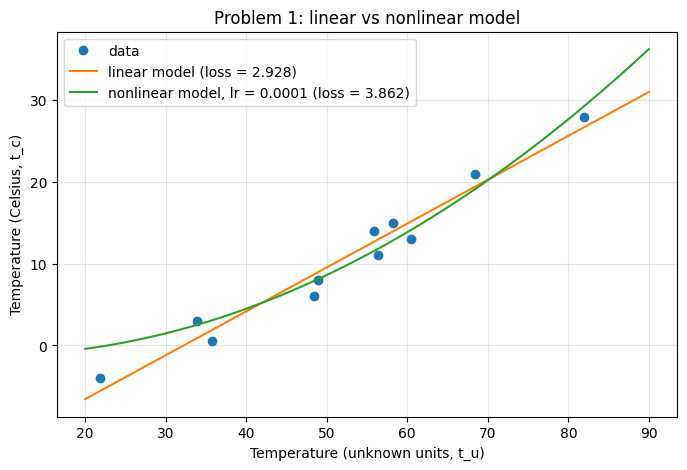

In [ ]:
t_range = torch.tensor(np.linspace(20, 90, 200), dtype=torch.float32)      # t_u values for drawing the curves
with torch.no_grad():
    p_lin = model_linear(0.1 * t_range, *params_lin)
    p_nl = model_nonlinear(0.1 * t_range, *params_nl)

plt.figure(figsize=(8, 5))
plt.plot(t_u.numpy(), t_c.numpy(), 'o', label='data')
plt.plot(t_range.numpy(), p_lin.numpy(), label=f'linear model (loss = {loss_lin:.3f})')
plt.plot(t_range.numpy(), p_nl.numpy(), label=f'nonlinear model, lr = {best_lr} (loss = {loss_nl:.3f})')
plt.xlabel('Temperature (unknown units, t_u)')
plt.ylabel('Temperature (Celsius, t_c)')
plt.title('Problem 1: linear vs nonlinear model')
plt.legend(); plt.grid(alpha=0.3); plt.show()

---
# Problem 2: Linear regression on the housing data (5 inputs)



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/My Drive/Intro-to-ML/Datasets/Housing.csv'
df = pd.read_csv(file_path)
print(df.shape)
df.head()

Mounted at /content/drive
(545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [ ]:
BINARY = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for c in BINARY:
    df[c] = df[c].map({'yes': 1, 'no': 0})

y = df['price'].values.astype(float)

# same 80/20 split as HW2
rng = np.random.default_rng(42)
perm = rng.permutation(len(df))
k = int(np.floor(0.8 * len(df)))
TR, VA = perm[:k], perm[k:]
print('training:', len(TR), '  validation:', len(VA))

def prepare(X):
    """Standardize with training statistics and convert to tensors."""
    X = X.astype(float)
    mu, sd = X[TR].mean(axis=0), X[TR].std(axis=0)
    Xs = (X - mu) / sd
    f32 = torch.float32
    return (torch.tensor(Xs[TR], dtype=f32), torch.tensor(Xs[VA], dtype=f32),
            torch.tensor(y[TR], dtype=f32), torch.tensor(y[VA], dtype=f32))

training: 436   validation: 109


## 2.a Model and training loop




In [ ]:
def model_house(X, params):
    return X @ params[1:] + params[0]

def r2(y_true, y_pred):
    return float(1 - ((y_true - y_pred) ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum())

def train_house(n_epochs, lr, X_tr, X_va, y_tr, y_va):
    params = torch.zeros(X_tr.shape[1] + 1, requires_grad=True)
    optimizer = optim.SGD([params], lr=lr)
    rows = []
    for epoch in range(1, n_epochs + 1):
        train_loss = loss_fn(model_house(X_tr, params), y_tr)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                p_va = model_house(X_va, params)
                val_loss = loss_fn(p_va, y_va)
            rows.append({'Epoch': epoch, 'Train loss': float(train_loss),
                         'Val loss': float(val_loss), 'Val R2': r2(y_va, p_va)})
            print(f'Epoch {epoch}, Training loss {float(train_loss):.4e}, '
                  f'Validation loss {float(val_loss):.4e}, Validation R2 {r2(y_va, p_va):.4f}')
    return params, pd.DataFrame(rows).set_index('Epoch')

def run_all_lrs(X_tr, X_va, y_tr, y_va):
    res = {}
    for lr in LRS:
        print(f'----- learning rate = {lr} -----')
        params, log = train_house(N_EPOCHS, lr, X_tr, X_va, y_tr, y_va)
        res[lr] = {'params': params, 'log': log}
        print()
    return res

## 2.b 5000 epochs with learning rates 0.1, 0.01, 0.001 and 0.0001

In [ ]:
FEAT_5 = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
X5_tr, X5_va, y_tr, y_va = prepare(df[FEAT_5].values)
res5 = run_all_lrs(X5_tr, X5_va, y_tr, y_va)

----- learning rate = 0.1 -----
Epoch 500, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 1000, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 1500, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 2000, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 2500, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 3000, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 3500, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 4000, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 4500, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743
Epoch 5000, Training loss 1.5471e+12, Validation loss 1.5018e+12, Validation R2 0.5743

----- learning rate = 0.01 -----
Epoch 500, Training loss 1.5471e+12, Validation loss 1.5014e+12, 

           Final train loss  Final val loss  Final val R2
lr=0.1           1.5471e+12      1.5018e+12        0.5743
lr=0.01          1.5471e+12      1.5018e+12        0.5743
lr=0.001         1.5471e+12      1.5014e+12        0.5744
lr=0.0001        4.6931e+12      4.1869e+12       -0.1869

best learning rate = 0.1
  bias                 4,749,521.0
  area                   719,953.0
  bedrooms               103,996.7
  bathrooms              624,093.1
  stories                469,274.0
  parking                290,992.9


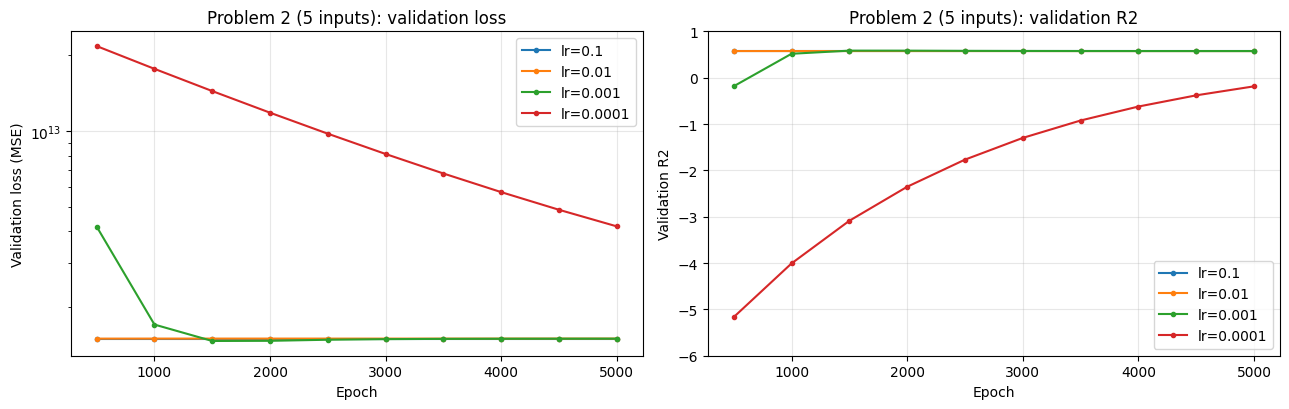

In [ ]:
def summarize(res, feats):
    s = pd.DataFrame({f'lr={lr}': {'Final train loss': res[lr]['log']['Train loss'].iloc[-1],
                                   'Final val loss': res[lr]['log']['Val loss'].iloc[-1],
                                   'Final val R2': res[lr]['log']['Val R2'].iloc[-1]} for lr in LRS}).T
    print(s.to_string(float_format=lambda v: f'{v:.4e}' if abs(v) > 100 else f'{v:.4f}'))
    # best = the fastest learning rate that reaches the lowest training loss (within 0.01%)
    low = min(res[lr]['log']['Train loss'].iloc[-1] for lr in LRS)
    best = [lr for lr in LRS if res[lr]['log']['Train loss'].iloc[-1] <= low * 1.0001][0]
    print(f'\nbest learning rate = {best}')
    names = ['bias'] + feats
    for n, p in zip(names, res[best]['params'].detach().numpy()):
        print(f'  {n:<16}{p:>16,.1f}')
    return best

def plot_losses(res, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for lr in LRS:
        log = res[lr]['log']
        ax[0].plot(log.index, log['Val loss'], marker='o', ms=3, label=f'lr={lr}')
        ax[1].plot(log.index, log['Val R2'], marker='o', ms=3, label=f'lr={lr}')
    ax[0].set_yscale('log'); ax[0].set_ylabel('Validation loss (MSE)'); ax[0].set_title(title + ': validation loss')
    ax[1].set_ylabel('Validation R2'); ax[1].set_ylim(-6, 1); ax[1].set_title(title + ': validation R2')
    for a in ax:
        a.set_xlabel('Epoch'); a.grid(alpha=0.3); a.legend()
    plt.tight_layout(); plt.show()

best5 = summarize(res5, FEAT_5)
plot_losses(res5, 'Problem 2 (5 inputs)')

## 2.c Comparison with HW2

.

In [ ]:
hw2 = {'5 inputs':  {'J_val': 7.509154e11, 'R2_val': 0.5743},
       '11 inputs': {'J_val': 5.659235e11, 'R2_val': 0.6791}}

def compare(res, best, key):
    log = res[best]['log']
    print(f'{"":<28}{"Val loss (MSE)":>18}{"Val R2":>10}')
    print(f'{"HW2 (NumPy GD)":<28}{2 * hw2[key]["J_val"]:>18.4e}{hw2[key]["R2_val"]:>10.4f}')
    print(f'{"HW5 (PyTorch, lr=" + str(best) + ")":<28}{log["Val loss"].iloc[-1]:>18.4e}{log["Val R2"].iloc[-1]:>10.4f}')

compare(res5, best5, '5 inputs')

                                Val loss (MSE)    Val R2
HW2 (NumPy GD)                      1.5018e+12    0.5743
HW5 (PyTorch, lr=0.1)               1.5018e+12    0.5743


---
# Problem 3: Linear regression with all input features




In [ ]:
furn = pd.get_dummies(df['furnishingstatus'], prefix='furn', drop_first=True).astype(int)
FEAT_ALL = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement',
            'hotwaterheating', 'airconditioning', 'parking', 'prefarea'] + list(furn.columns)
df_all = pd.concat([df, furn], axis=1)
print(FEAT_ALL)

Xa_tr, Xa_va, y_tr, y_va = prepare(df_all[FEAT_ALL].values)
res_all = run_all_lrs(Xa_tr, Xa_va, y_tr, y_va)

['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furn_semi-furnished', 'furn_unfurnished']
----- learning rate = 0.1 -----
Epoch 500, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914
Epoch 1000, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914
Epoch 1500, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914
Epoch 2000, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914
Epoch 2500, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914
Epoch 3000, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914
Epoch 3500, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914
Epoch 4000, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914
Epoch 4500, Training loss 1.1348e+12, Validation loss 1.0888e+12, Validation R2 0.6914


           Final train loss  Final val loss  Final val R2
lr=0.1           1.1348e+12      1.0888e+12        0.6914
lr=0.01          1.1348e+12      1.0888e+12        0.6914
lr=0.001         1.1348e+12      1.0888e+12        0.6914
lr=0.0001        4.2474e+12      3.8942e+12       -0.1039

best learning rate = 0.1
  bias                 4,749,521.0
  area                   542,747.0
  bedrooms                82,200.4
  bathrooms              553,155.7
  stories                364,800.8
  mainroad               153,442.1
  guestroom              125,300.1
  basement                90,801.4
  hotwaterheating        188,705.9
  airconditioning        394,479.6
  parking                207,873.3
  prefarea               330,302.7
  furn_semi-furnished        32,648.7
  furn_unfurnished      -137,667.8


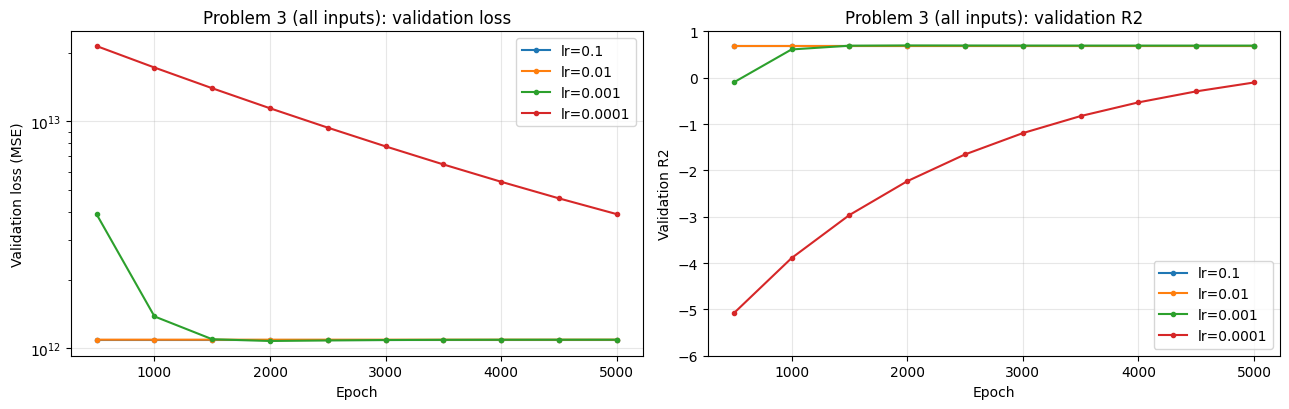

In [ ]:
best_all = summarize(res_all, FEAT_ALL)
plot_losses(res_all, 'Problem 3 (all inputs)')

In [ ]:
compare(res_all, best_all, '11 inputs')

                                Val loss (MSE)    Val R2
HW2 (NumPy GD)                      1.1318e+12    0.6791
HW5 (PyTorch, lr=0.1)               1.0888e+12    0.6914
